# SNO 2026
# Processando dados de CTD com Python
### Prof. Guto Schettini
### 2-Nov-2026
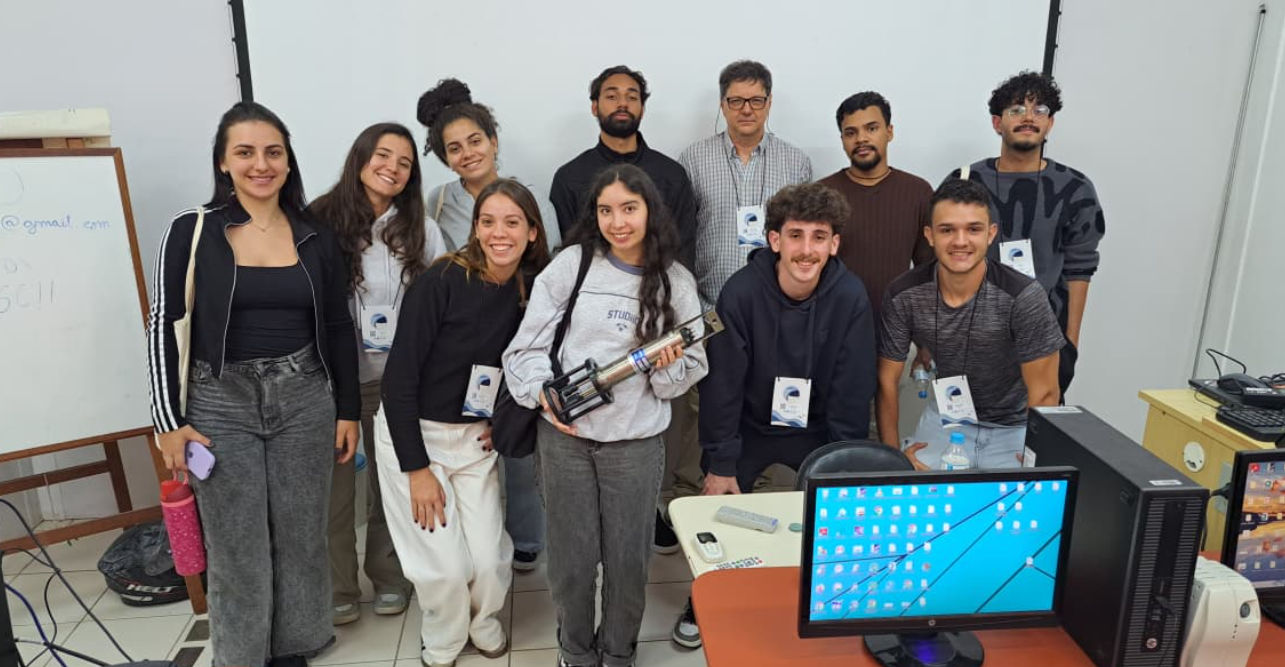

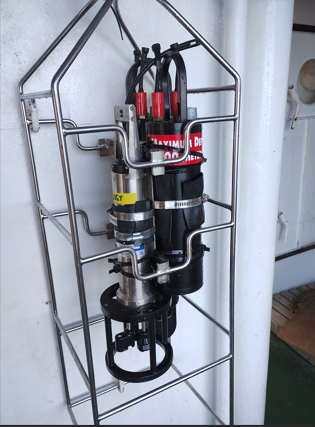
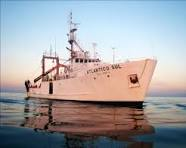

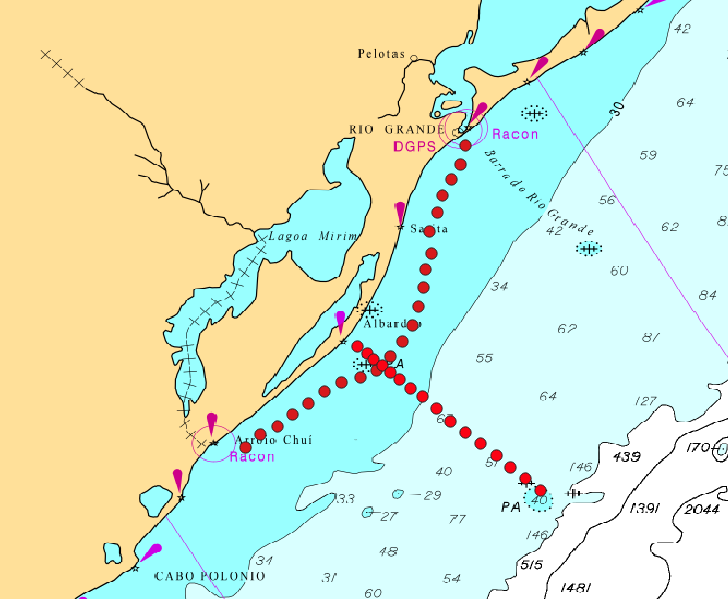

# 1) Acessar os dados (carregar!) 
- Arquivo formato ASCII - American Standard Code for Information Interchange
- Explore o conteúdo utilizando um editor de text (notepad ou qualquer outro)  
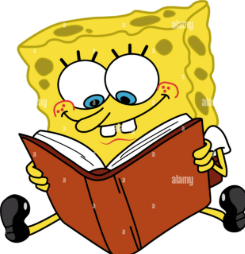

In [2]:
# criand uma variável 'string' que contem o nome do arquivo
arquivo = '202311091101_ASTD102-ALC-R02_0046_110156.csv'

# abrindo o arquivo e criando 'io' que é um objeto 'wrapper'
with open(arquivo, encoding='utf-8') as io:
    linhas = io.readlines()

# A tabulação é importante! Tudo que estiver tabulado é 
# porque está dentro da instância do 'with'

# No 'with' criamos o objeto 'linhas' que é uma LISTA. Lista é uma estrutura
# do Python

# o que está em branco são variáveis, que podem ser mudadas ao gosto do cliente...

- Explorando os dados e verificando onde está o cabeçalho e onde começam os dados

In [3]:
for i, linha in enumerate(linhas[:70]):
    print(i, linha)

0 ﻿// JOGOS

1 // Version 1.01

2 // File Date:2023/11/09 11:14:38

3 // (C) 2020 JFE Advantech Co., Ltd.

4 

5 [Format]

6 FormatVersion=1.00

7 DataFormat=1

8 Delimiter=0

9 Model=JOGOS

10 

11 [Head]

12 SondeName=ASTD102-ALC-R02

13 SondeNo=0046

14 SensorType=D0D1T1C1C2K0U3O0TOB0

15 SensorType2=06070303000202020302

16 Channel=10

17 Comment=

18 MeasMode=0

19 

20 PreHeat=5000

21 Interval=100

22 SampleCnt=5510

23 

24 StartTime=2023/11/09 11:02:01

25 EndTime=2023/11/09 11:11:11

26 

27 DepAdjRho=1.0197

28 

29 ECA=0

30 ECB=1

31 ECDeg=25

32 ECCoef=0.022

33 

34 CHLA=0

35 CHLB=1

36 

37 PC_SWA=0

38 PC_SWB=0

39 PC_SWC=0

40 PC_SWD=0

41 

42 DepthZero=0

43 StartDepthA=0

44 StartDepthB=0

45 

46 FilmNo=200634BA

47 

48 CondDepB=0

49 DepM=0

50 

51 FormulaDOM=0

52 ExplanationDOM=Weiss (1970)

53 

54 CoefDate=2020/12/14

55 

56 Ch1=-3.255494e-01,+1.035111e-04,+0.000000e+00,+0.000000e+00,+0.000000e+00,+0.000000e+00,+0.000000e+00,+0.000000e+00,

57 Ch2=0.00000

- Sabendo que o cabeçalho é a linha com índice 68

In [4]:
cabecalho = linhas[68]
print(cabecalho)

Measurement Date/Time,Press. [dbar],Temp. [℃],Salinity,Cond. [mS/cm],EC [μS/cm],Density [kg/m3],SigmaT,Chl-Flu. [ppb],Chl-a [ppb],Turb. [FTU],DO [%],DO [mg/l],DO [μmol/l],Batt. [V]



- quebrando a string com a vírgula, e mostrando...

In [5]:
cabecalho = cabecalho.split(',')
for i, c in enumerate(cabecalho):
    print(i, c)

0 Measurement Date/Time
1 Press. [dbar]
2 Temp. [℃]
3 Salinity
4 Cond. [mS/cm]
5 EC [μS/cm]
6 Density [kg/m3]
7 SigmaT
8 Chl-Flu. [ppb]
9 Chl-a [ppb]
10 Turb. [FTU]
11 DO [%]
12 DO [mg/l]
13 DO [μmol/l]
14 Batt. [V]



- prototipando o processamento dos dados

In [6]:
dado_1 = linhas[69]
print(dado_1)

2023/11/09 11:02:01,-0.860,16.905,0.033,0.053,63.887,998.814,-1.182,0.00,0.00,3.68,100.32,9.968,311.521,8.43,



In [7]:
dado_1 = dado_1.split(',')
print(dado_1)

['2023/11/09 11:02:01', '-0.860', '16.905', '0.033', '0.053', '63.887', '998.814', '-1.182', '0.00', '0.00', '3.68', '100.32', '9.968', '311.521', '8.43', '\n']


- cada linha é uma string
- com o 'split', converte em uma lista de strings
- repare que apareceu '\n', que é um código de quebra de linha e fica invisível nos arquivos
- o tempo tem que ser tratado separado, mas os demais campos são 'floats'
- Agora, pegando cada linha de dados, quebrando a string, convertendo em 'float' e armazenando em outra lista

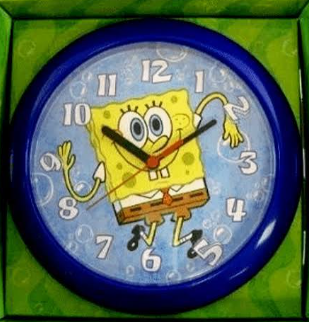
- O tempo no Python deve ser tratado com um objeto 'datetime'... para isso podemos usar o pacote 'dateutils.parser' que converte strings de tempo em objeto datetime!
- Neste notebook estamos importando pacotes quando estes se tornam necessários... normalmente todos os pacotes devem ser importados no início do notebook para evitar confusão!

In [8]:
# importanto pacote! Na verdade, só uma função do pacote
from dateutil.parser import parse

In [9]:
print(dado_1[0], type(dado_1[0]))
print(parse(dado_1[0]), type(parse(dado_1[0])))
# Embora visualmente pareça a mesma coisa, não são. Um é uma string,
# o outro é um objeto datetime!

2023/11/09 11:02:01 <class 'str'>
2023-11-09 11:02:01 <class 'datetime.datetime'>


- Processando todas as linhas...
- for linha in linhas[69:-1]:

In [10]:
# cria uma lista vazia
dados = []
tempo = []
# for linha in linhas[69:]:   # se usar deste jeito, irá aparecer um erro
for linha in linhas[69:-1]:
    liq = linha.split(',')

    #'guarda' o tempo na lista vazia criada
    tempo.append(parse(liq[0]))
    # converte as strings em floats... isto é um procedimento 'list compreension'
    floats = [float(x) for x in liq[1:-1]]
    # guarda os dados
    dados.append(floats)

In [11]:
print(type(tempo), len(tempo))
print(type(dados), len(dados))
print(tempo[0])
print(dados[0])

<class 'list'> 5510
<class 'list'> 5510
2023-11-09 11:02:01
[-0.86, 16.905, 0.033, 0.053, 63.887, 998.814, -1.182, 0.0, 0.0, 3.68, 100.32, 9.968, 311.521, 8.43]


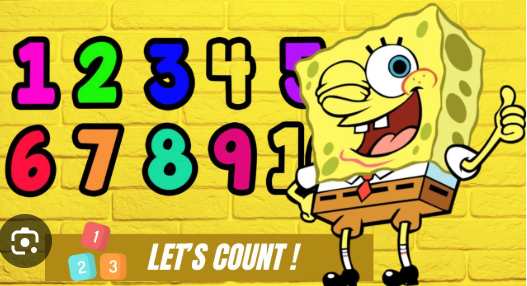

## Numeros --> Numpy
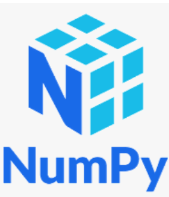

In [12]:
import numpy as np

In [13]:
dados = np.vstack(dados)

print(type(dados), len(dados), dados.shape)
print(dados[0])

<class 'numpy.ndarray'> 5510 (5510, 14)
[-8.60000e-01  1.69050e+01  3.30000e-02  5.30000e-02  6.38870e+01
  9.98814e+02 -1.18200e+00  0.00000e+00  0.00000e+00  3.68000e+00
  1.00320e+02  9.96800e+00  3.11521e+02  8.43000e+00]


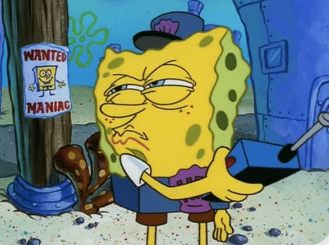
- 'listas' são objetos do Python nativo... são sequência ordenadas, porém mutáveis, de objetos
- 'arrays' são objetos do Numpy. São estruturas de dados homogêneas (mesmo tipo de objetos), e multidimensionais (listas não tem dimensões!)

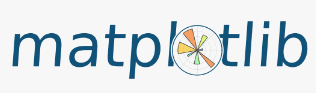
- Para fazer gráficos --> Matplotbib

In [14]:
import matplotlib.pyplot as plt

- Vamos inicialmente explorar o tempo e a pressão... 

Text(0, 0.5, 'Pressao (dB)')

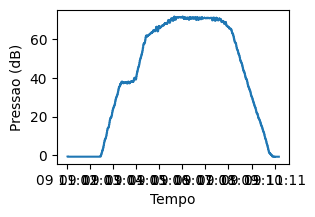

In [15]:
plt.figure(figsize=(3,2))
plt.plot(tempo, dados[:,0])
plt.xlabel('Tempo')
plt.ylabel('Pressao (dB)')

- As legendas do 'tempo' ficaram esculhambadas...
- Para arrumar, preciamos do 'matplotlib.dates'

In [16]:
import matplotlib.dates as mdates

Text(0, 0.5, 'Pressao (dB)')

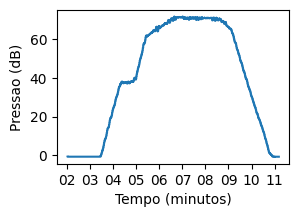

In [17]:
plt.figure(figsize=(3,2))
plt.plot(tempo, dados[:,0])
plt.gca().xaxis.set_major_locator(mdates.MinuteLocator(interval=1))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%M'))
plt.xlabel('Tempo (minutos)')
plt.ylabel('Pressao (dB)')

# Perfil vertical

Text(0, 0.5, 'Profundidade (m)')

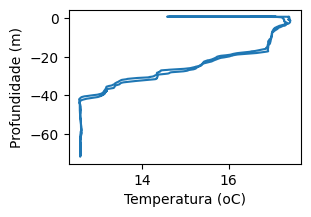

In [18]:
plt.figure(figsize=(3,2))
plt.plot(dados[:,1], -dados[:,0])
plt.xlabel('Temperatura (oC)')
plt.ylabel('Profundidade (m)')

- Lembrando... o CTD é ligado e desligado no convés do barco...
- O início e o fim dos dados não são dados na água...
- Uma opção e selecionar os dados pela pressao!
- Tipo, quais os dados em que a pressão é maior que um valor de referência?

Text(0, 0.5, 'Profundidade (m)')

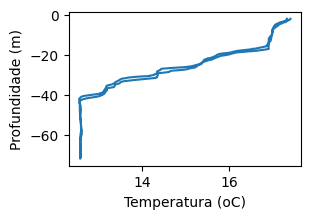

In [19]:
pressao_referencia = 2 #dB
idx = np.where(dados[:,0] > pressao_referencia)[0]

plt.figure(figsize=(3,2))
plt.plot(dados[idx,1], -dados[idx,0])
plt.xlabel('Temperatura (oC)')
plt.ylabel('Profundidade (m)')

- Há duas linhas... quando o CTD desce, e quando ele sobe...
- Isso sempre ocorre, e escolhemos uma. Nós aqui escolhemos a descida
- Então, para separar somente a descida, não dá para usar o 'where'... a receita de bolo é...

In [22]:
pressao_referencia = 2 #dB

dados_descida = []
for i in range(len(dados)):
    # testa para verificar se a pressão é maior que a referencia
    if dados[i,0] > pressao_referencia:
        # se for verdade, quardo em uma nova lista a linha dos dados
        dados_descida.append(dados[i,:])
        # e estabeleço uma nova referência, para pegar só pressão aumentando
        pressao_referencia = dados[i,0]

dados_descida = np.vstack(dados_descida)
print(dados_descida.shape)

(1092, 14)


Text(0, 0.5, 'Profundidade (m)')

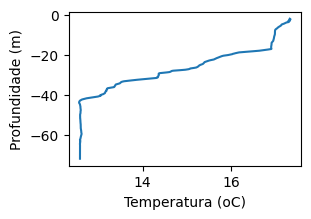

In [24]:
plt.figure(figsize=(3,2))
plt.plot(dados_descida[:,1], -dados_descida[:,0])
plt.xlabel('Temperatura (oC)')
plt.ylabel('Profundidade (m)')

- Ok... agora temos apenas os dados de descida, mas...
- O CTD registra dados em função do tempo (em 10 Hz), e caso tenha ocorrido variação da taxa de descida do CTD (o que de fato ocorreu, vendo a variação da pressão no tempo), se formos fazer o diagrama TS os dados podem apresentar uma tendência incorreta. Ou, temos que obter um perfil vertical com valores variando regularmente com a profundide, digamos em intervalos de 1 m.
- A opção mais simples é fazer uma interpolação
- Outra opção seria achar os valores médios para cada intervalo de profundidade

Text(0, 0.5, 'Profundidade (m)')

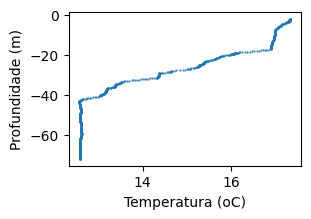

In [25]:
plt.figure(figsize=(3,2))
plt.plot(dados_descida[:,1], -dados_descida[:,0], '.', ms=1)
plt.xlabel('Temperatura (oC)')
plt.ylabel('Profundidade (m)')

#### Interpolando

- Para facilitar, vou separar as variáveis de interesse, e depois proceder com o processamento!

In [27]:
pressao = dados_descida[:,0]
temperatura = dados_descida[:,1]
salinidade = dados_descida[:,2]

# criando um array de pressão onde vou reamostrar os dados originais
# da pressão mínima (lá de cima = 2), até a máxima, em intervalos de 1 dB
pressao_i = np.arange(2, np.max(pressao), 1)

# interpolando
temperatura_i = np.interp(pressao_i, pressao, temperatura)
salinidade_i = np.interp(pressao_i, pressao, salinidade)

# Gráfico Bonito!

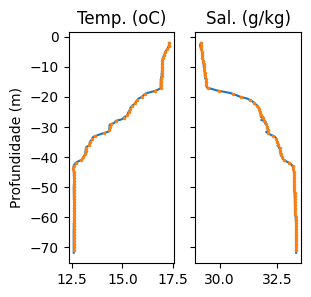

In [43]:
fig, axs = plt.subplots(1,2, figsize=(3,3))
axs[0].plot(temperatura, -pressao)
axs[0].plot(temperatura_i, -pressao_i, '.', ms=3)
axs[0].set_title('Temp. (oC)')
axs[0].set_ylabel('Profundidade (m)')

axs[1].plot(salinidade, -pressao)
axs[1].plot(salinidade_i, -pressao_i, '.', ms=3)
axs[1].set_title('Sal. (g/kg)')
axs[1].set_yticklabels('')
plt.show()

- Embora os dados originais (linha azul) e os dados interpolado (pontos laranja) sejam praticamente iguais, os dados interpolados são função da profundidade, com resolução de 1 m. Os dados originais são em função do tempo, e a variação da profundiade não é homogênea.
- Fazendo o digrama TS, isso fica mais claro! 


Text(0, 0.5, 'Temperatura (oC)')

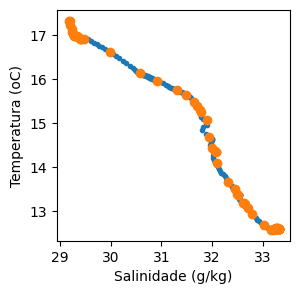

In [48]:
plt.figure(figsize=(3,3))
plt.plot(salinidade, temperatura, '.')
plt.plot(salinidade_i, temperatura_i, 'o')
plt.xlabel('Salinidade (g/kg)')
plt.ylabel('Temperatura (oC)')